# AA 279B Homework 1


## Problem 1

In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import numpy as np
from scipy.integrate import solve_ivp
from scipy.optimize import root_scalar
import matplotlib.pyplot as plt

In [3]:
# km3/s2
MU_PLUTO = 870.9
MU_CHARON = 101.0

# km
r_PLUTO_CHARON = 19571.0 
R_PLUTO = 1184.0
R_CHARON = 603.5

### Part (a)

In [4]:
T_pluto = 2 * np.pi * np.sqrt(R_PLUTO**3 / MU_PLUTO)

print(f"T_pluto: {T_pluto} sec ({T_pluto/60} min)")

T_pluto: 8674.077071700143 sec (144.5679511950024 min)


### Part (b)

In [5]:
mu_star = MU_CHARON / (MU_CHARON + MU_PLUTO)

# Barycenter -> pluto
r_bc_pluto = mu_star * r_PLUTO_CHARON
inside_pluto = r_bc_pluto < R_PLUTO

# Barycenter -> charon
r_bc_charon = (1 - mu_star) * r_PLUTO_CHARON


print(f"Barycenter distance from Pluto: {r_bc_pluto:.2f}km")
print(f"Inside pluto? ({R_PLUTO:.2f}km): {inside_pluto}")

Barycenter distance from Pluto: 2033.82km
Inside pluto? (1184.00km): False


### Part (c)

In [6]:
w_pluto_charon = np.sqrt( (MU_PLUTO + MU_CHARON) / r_PLUTO_CHARON**3)

In [7]:
# No direction, just values

def a_pluto(x):
    return MU_PLUTO / (x + r_bc_pluto)**2
    
def a_charon(x):
    return MU_CHARON / (x - r_bc_charon)**2
    
def a_cent(x):
    return w_pluto_charon**2*x

In [8]:
# Lowkey using arbitrary bounds

# Force balance 
r_L1 = root_scalar(
    lambda x: a_pluto(x) - a_charon(x) - a_cent(x),
    bracket=[0, r_bc_charon - 0.001]).root


print(f"L1 location: {r_L1:.2f} km (from barycenter)")
print(f"             {(r_L1 + r_bc_pluto):.2f} km (from pluto)")
print(f"             {(r_bc_charon - r_L1):.2f} km (from charon)")

L1 location: 11774.28 km (from barycenter)
             13808.10 km (from pluto)
             5762.90 km (from charon)


In [9]:
# Completeness

r_L2 = root_scalar(
    lambda x: a_pluto(x) + a_charon(x) - a_cent(x),
    bracket=[r_bc_charon - 0.001, r_bc_charon*2]).root

r_L3 = root_scalar(
    lambda x: -a_pluto(x) - a_charon(x) - a_cent(x),
    bracket=[-r_bc_charon * 2, -r_bc_pluto + 0.001]).root

x_L4_L5 = (r_PLUTO_CHARON - r_bc_pluto) / 2
y_L4_L5 = r_PLUTO_CHARON * np.sqrt(3) / 2

In [10]:
def pe_eff(x, y, mu1, mu2, w):
    assert mu1 > mu2
    r_1 = np.sqrt( (x + r_bc_pluto)**2 + y**2)
    r_2 = np.sqrt( (x - r_bc_charon)**2 + y**2)
    
    return -mu1/r_1 -mu2/r_2 - w**2 / 2 * (x**2 + y**2)

def ke_eff(v):
    return 1/2 * (v[0]**2 + v[1]**2 + v[2]**2)

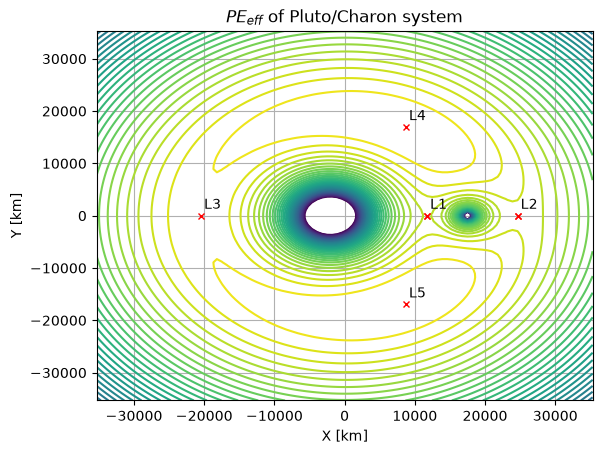

In [11]:
scale = 3
x = np.linspace(-r_L1*scale, r_L1*scale, 100)
y = np.linspace(-r_L1*scale, r_L1*scale, 100)

X, Y = np.meshgrid(x, y)
Z = pe_eff(X, Y, MU_PLUTO, MU_CHARON, w_pluto_charon)

levels = np.linspace(2*pe_eff(r_bc_charon*0.9,0, MU_PLUTO, MU_CHARON, w_pluto_charon), np.max(Z), 40)

plt.contour(X, Y, Z, levels)
plt.plot(r_L1, 0, "rx", markersize=5)
plt.plot(r_L2, 0, "rx", markersize=5)


xs = [r_L1, r_L2, r_L3]
labels = ["L1", "L2", "L3"]
for l_point, label in zip(xs, labels):
    plt.plot(l_point, 0, "rx", markersize=5)
    plt.annotate(label, xy=(l_point,0),
                 textcoords="offset points", xytext=(2,5))
    
plt.plot(x_L4_L5, y_L4_L5, "rx", markersize=5)
plt.plot(x_L4_L5, -y_L4_L5, "rx", markersize=5)
plt.annotate("L4", xy=(x_L4_L5, y_L4_L5),
                 textcoords="offset points", xytext=(2,5))
plt.annotate("L5", xy=(x_L4_L5, -y_L4_L5),
                 textcoords="offset points", xytext=(2,5))

plt.title(r"$PE_{eff}$ of Pluto/Charon system")
plt.xlabel("X [km]")
plt.ylabel("Y [km]")
plt.grid(True)
plt.show()

## Problem 2

### Part (a)

In [ ]:
def synodic_dynamics(state, mu1, mu2, R1, R2, w_s):
    
    assert mu1 > mu2
    assert R1 < R2
    
    x, y, z, x_dot, y_dot, z_dot = state
    
    r_1_sat = np.sqrt((x + R1)**2 + y**2 + z**2)
    r_2_sat = np.sqrt((x - R2)**2 + y**2 + z**2)
    
    x_ddot = (
        -mu1 * (x + R1) / (r_1_sat**3)
        -mu2 * (x - R2) / (r_2_sat**3)
        + 2 * w_s * y_dot
        + w_s**2 * x)
    
    y_ddot = (
        -mu1 * y / (r_1_sat**3)
        -mu2 * y / (r_2_sat**3)
        - 2 * w_s * x_dot
        + w_s**2 * y)
    
    z_ddot = (
        -mu1 * z / (r_1_sat**3)
        -mu2 * z / (r_2_sat**3))
    
    return np.array([x_dot, y_dot, z_dot, x_ddot, y_ddot, z_ddot])

### Part (b)

In [13]:
# km3/m2
MU_EARTH = 398600
MU_MOON = 4903

# km
r_EARTH_MOON = 384400
R_EARTH = 6378.0
R_MOON = 1738.0 

# Barycenter
r_bc_earth = MU_MOON / (MU_MOON + MU_EARTH) * r_EARTH_MOON
r_bc_moon = MU_EARTH / (MU_MOON + MU_EARTH) * r_EARTH_MOON

# w_s
w_earth_moon = np.sqrt( (MU_EARTH + MU_MOON) / r_EARTH_MOON**3)

In [ ]:
def earth_moon_synodic_dynamics(t, state):
    del t
    return synodic_dynamics(state, MU_EARTH, MU_MOON, r_bc_earth, r_bc_moon, w_earth_moon)

In [15]:
# Initial conditions
state0 = np.zeros(6)

rho_earth_sat = 200 + R_EARTH
phi = np.deg2rad(47.70061087)
v_inj = 10.92367104 

# x,y
state0[0] = -rho_earth_sat*np.cos(phi) - r_bc_earth
state0[1] = -rho_earth_sat*np.sin(phi)

# vx,vy
state0[3] =  v_inj * np.sin(phi)
state0[4] = -v_inj * np.cos(phi)

In [ ]:
DAY_TO_SEC = 24 * 60 * 60

t_span = (0, 6 * DAY_TO_SEC)
sol = solve_ivp(earth_moon_synodic_dynamics, t_span, state0, method='LSODA', rtol=1e-6, atol=1e-9)

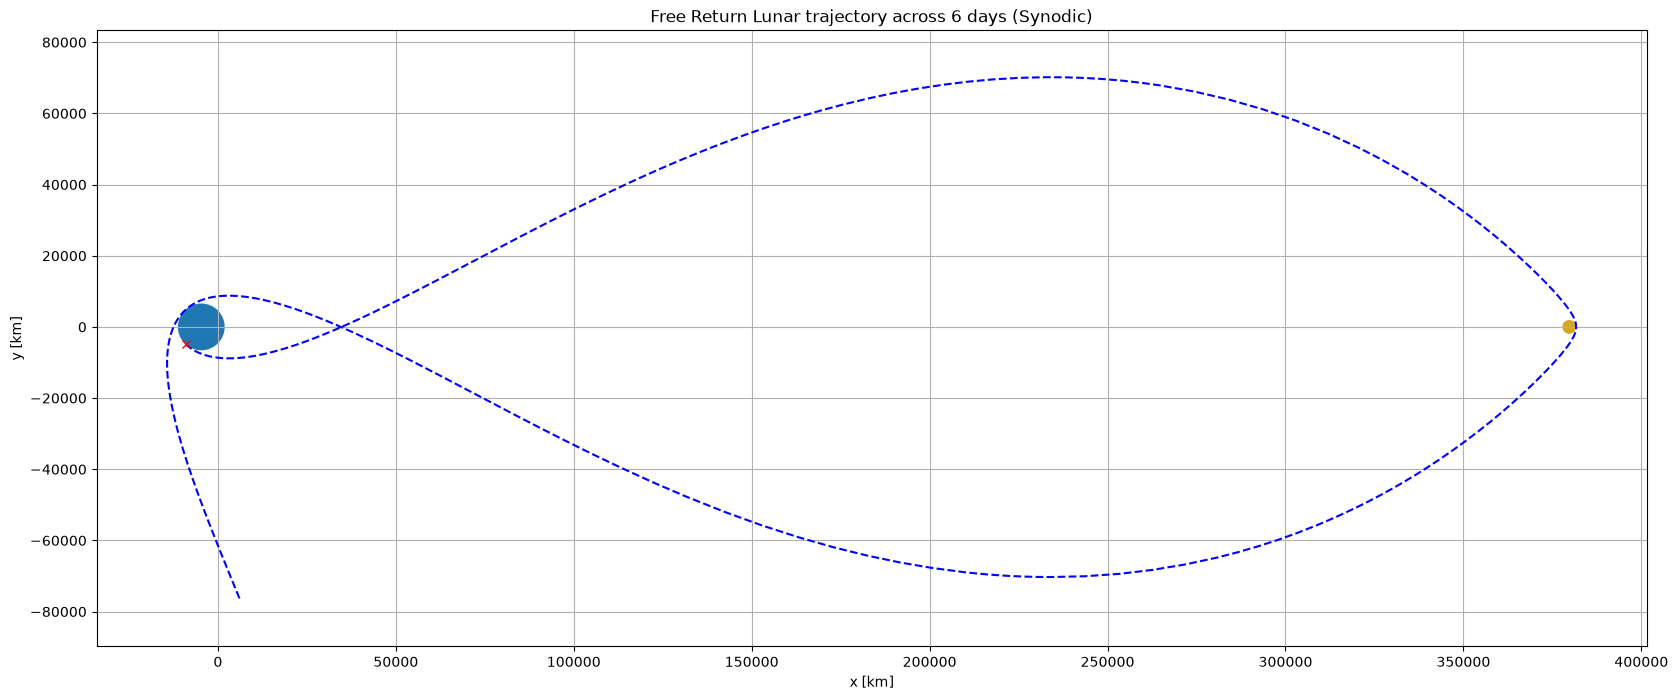

In [17]:
fig, ax = plt.subplots(figsize=(20, 8))
ax.set_title('Free Return Lunar trajectory across 6 days (Synodic)')

# Trajectory
ax.plot(sol.y[0], sol.y[1], 'b--', label='Trajectory')
ax.plot(sol.y[0,0], sol.y[1,1], 'rx', label='Initial position')

# Bodies
# ax.plot(-r_bc_earth, 0, "bo", markersize=5, label="Earth")
# ax.plot(r_bc_moon, 0, "o", color="goldenrod", markersize=5, label="Moon")
ax.add_patch(plt.Circle((-r_bc_earth,0), R_EARTH, color='tab:blue', fill=True))
ax.add_patch(plt.Circle((r_bc_moon,0), R_MOON, color='goldenrod', fill=True))

ax.set_xlabel('x [km]')
ax.set_ylabel('y [km]')
ax.set_aspect('equal', adjustable='datalim')

ax.grid(True)
plt.show()

### Part (c)
The trajectory is interesting because it seems to be a free return trajectory that is not captured by the Moon's gravity. This is useful for human spaceflight so that in the case of an emergency, the crew is able to automatically return.

In [18]:
rs_moon_sat = sol.y[0:3] - np.array([r_bc_moon, 0, 0])[:,None]
r_moon_sat = np.apply_along_axis(np.linalg.norm, 0, rs_moon_sat)

perilune = np.min(r_moon_sat)
t_perilune_day = sol.t[np.argmin(r_moon_sat)] / DAY_TO_SEC

print(f"Perilune ({perilune:.2f}km) at {t_perilune_day:.1f} days")

Perilune (1956.94km) at 2.9 days


### Part (d)

In [19]:
thetas = w_earth_moon * sol.t

dcms_s_wrt_i = np.zeros((len(sol.t), 3, 3))

dcms_s_wrt_i[:, 0, 0] = np.cos(thetas)
dcms_s_wrt_i[:, 0, 1] = -np.sin(thetas)
dcms_s_wrt_i[:, 1, 0] = np.sin(thetas)
dcms_s_wrt_i[:, 1, 1] = np.cos(thetas)
dcms_s_wrt_i[:, 2, 2] = 1

In [20]:
r_sat_inertial = np.array([dcm @ v for dcm,v in zip(dcms_s_wrt_i, sol.y[0:3].T)])

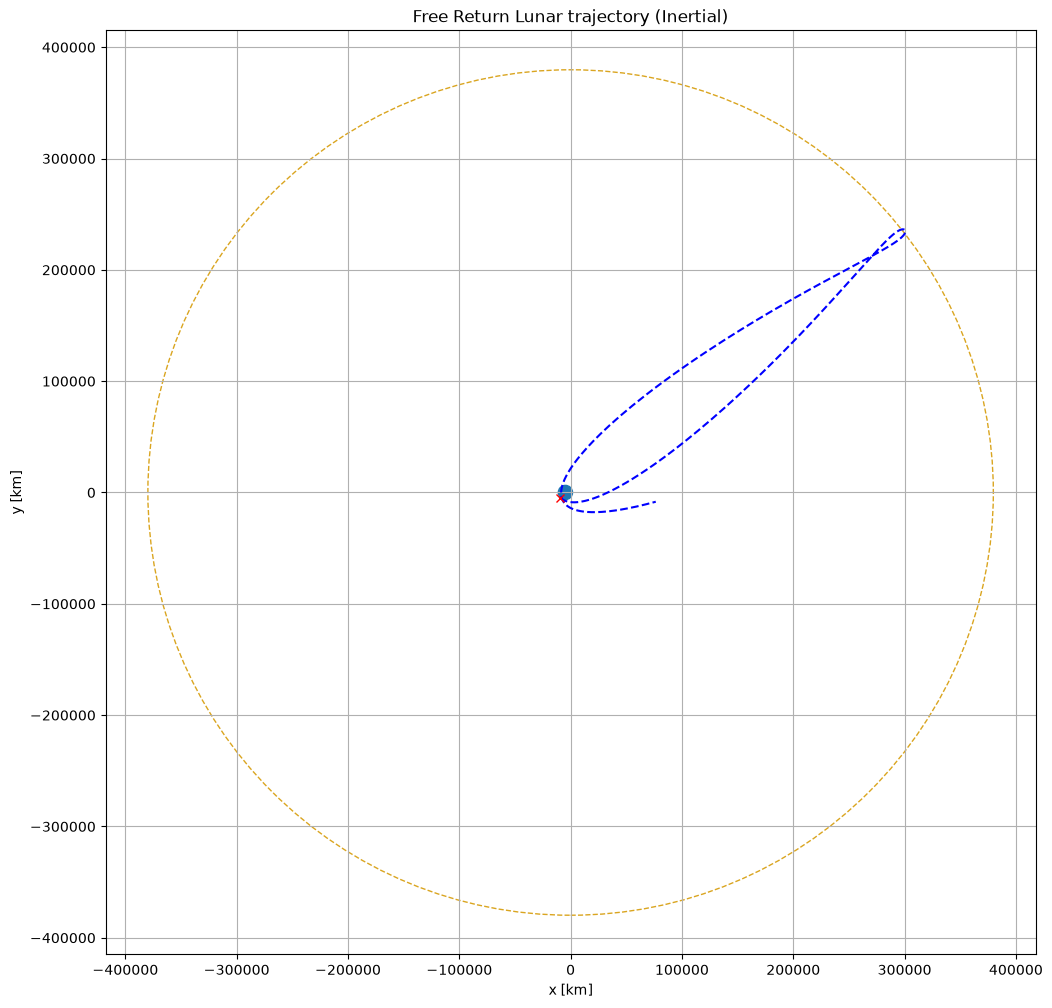

In [21]:
fig, ax = plt.subplots(figsize=(12, 12))
ax.set_title('Free Return Lunar trajectory (Inertial)')

# Trajectory
ax.plot(r_sat_inertial[:,0], r_sat_inertial[:,1], 'b--', label='Trajectory')
ax.plot(r_sat_inertial[0,0], r_sat_inertial[1,1], 'rx', label='Initial position')

# Bodies
ax.add_patch(plt.Circle((-r_bc_earth,0), R_EARTH, color='tab:blue', fill=True))
# ax.add_patch(plt.Circle((0,0), r_bc_earth, edgecolor='tab:blue', fill=False))
ax.add_patch(plt.Circle((0,0), r_bc_moon, edgecolor='goldenrod', linestyle='--', fill=False))

ax.set_xlabel('x [km]')
ax.set_ylabel('y [km]')
ax.set_aspect('equal', adjustable='datalim')

ax.grid(True)
plt.show()

In [22]:
# Inertial velocity

# Typing this in particular
def v_s_to_v_i(v_s: np.ndarray, r_i: np.ndarray, w: float):
    w_vec = [0, 0, w] # Same in both frames
    v_i = v_s + np.cross(w_vec, r_i)
    return v_i

v_s = np.array([dcm @ v for dcm,v in zip(dcms_s_wrt_i, sol.y[3:6].T)])
v_sat_inertial = np.array([v_s_to_v_i(v, r, w_earth_moon) for v,r in zip(v_s, r_sat_inertial)])

In [23]:
v_sat_inertial[0]

array([ 8.09253281, -7.37592992,  0.        ])

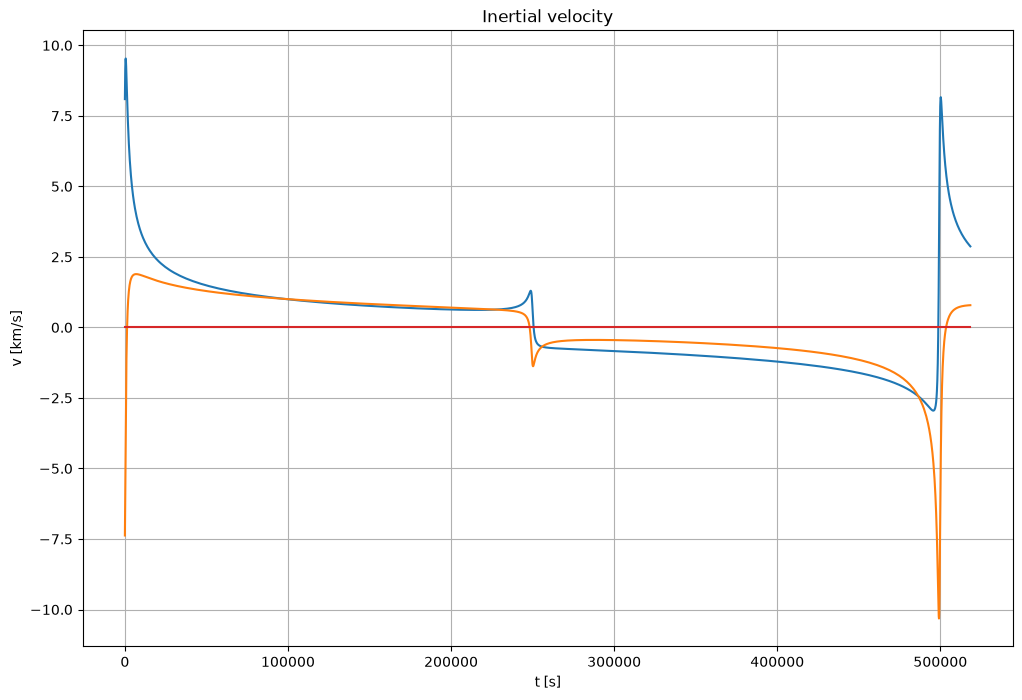

In [29]:
fig, ax = plt.subplots(figsize=(12, 8))
ax.set_title('Inertial velocity')

ax.plot(sol.t, v_sat_inertial[:,0], 'tab:blue', label="vx")
ax.plot(sol.t, v_sat_inertial[:,1], 'tab:orange', label="vy")
ax.plot(sol.t, v_sat_inertial[:,2], 'tab:red', label="vz")

ax.set_xlabel('t [s]')
ax.set_ylabel('v [km/s]')

ax.grid(True)
plt.show()

### Part (e)

In [25]:
E_eff_earth_moon = [pe_eff(pos[0], pos[1], MU_EARTH, MU_MOON, w_earth_moon) + ke_eff(vel) for pos,vel in zip(r_sat_inertial, v_sat_inertial)]

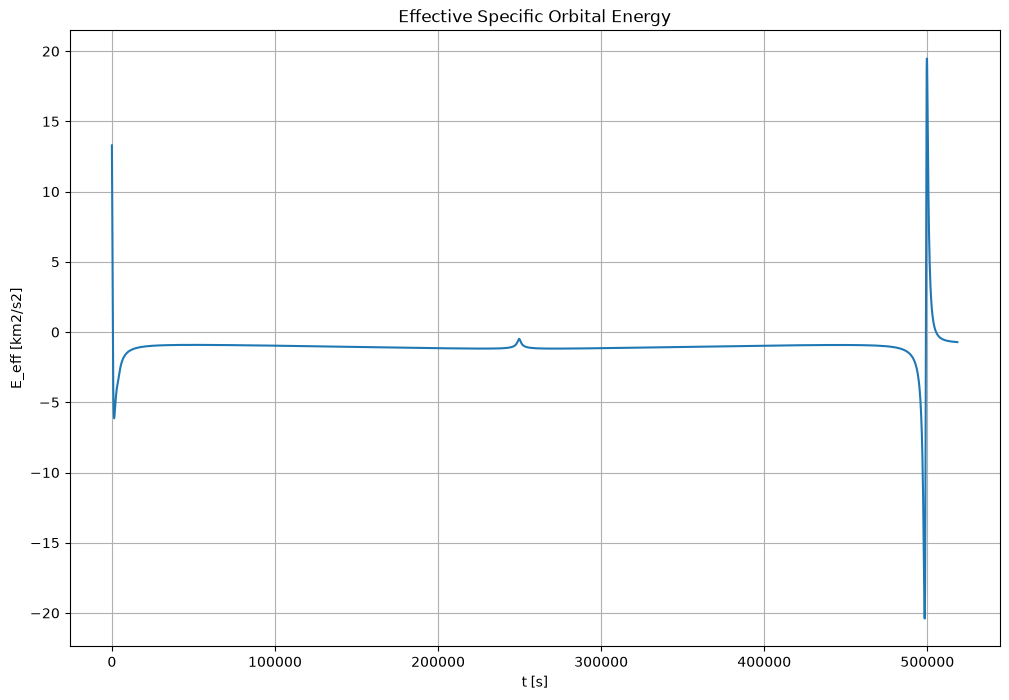

In [ ]:
fig, ax = plt.subplots(figsize=(12, 8))
ax.set_title('Effective Specific Orbital Energy')

ax.plot(sol.t, E_eff_earth_moon)

ax.set_xlabel('t [s]')
ax.set_ylabel('E_eff [km2/s2]')

ax.grid(True)
plt.show()

### Part (e)

In [54]:
def inertial_dynamics(state, mu1, mu2, R1, R2, w_s):
    assert mu1 > mu2
    assert R1 < R2
    
    x, y, x_dot, y_dot, x_1, y_1, x_2, y_2 = state
    
    r_1_sat = np.sqrt((x - x_1)**2 + (y - y_1)**2)
    r_2_sat = np.sqrt((x - x_2)**2 + (y - y_2)**2)
    
    x_ddot = (
        -mu1 * (x - x_1) / (r_1_sat**3)
        -mu2 * (x - x_2) / (r_2_sat**3))
    
    y_ddot = (
        -mu1 * (y - y_1) / (r_1_sat**3)
        -mu2 * (y - y_2) / (r_2_sat**3))
    
    # v = w x r
    x_1_dot = -w_s * y_1
    y_1_dot =  w_s * x_1
        
    x_2_dot = -w_s * y_2
    y_2_dot =  w_s * x_2
    
    return np.array([x_dot, y_dot, x_ddot, y_ddot, x_1_dot, y_1_dot, x_2_dot, y_2_dot])

def earth_moon_inertial_dynamics(t, state):
    del t
    return inertial_dynamics(state, MU_EARTH, MU_MOON, r_bc_earth, r_bc_moon, w_earth_moon)

In [56]:
state0_inertial = np.concatenate((r_sat_inertial[0, 0:2], v_sat_inertial[0, 0:2], [-r_bc_earth, 0], [r_bc_moon, 0]))

sol_inertial = solve_ivp(earth_moon_inertial_dynamics, t_span, state0_inertial, method='LSODA', rtol=1e-6, atol=1e-9)

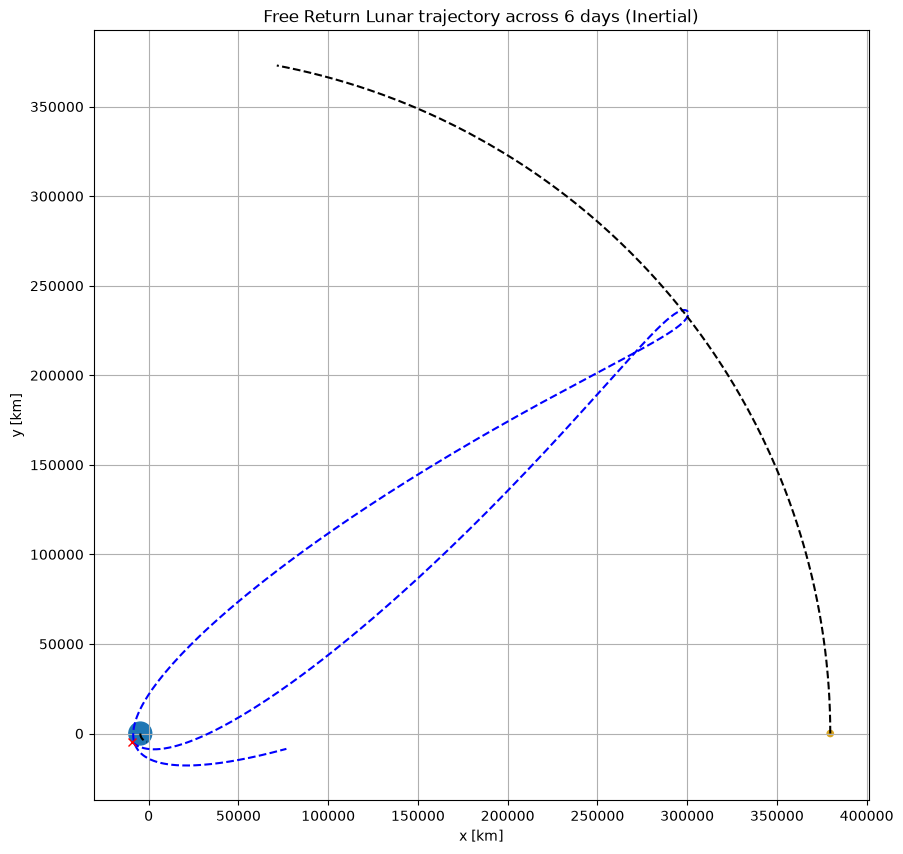

In [64]:
fig, ax = plt.subplots(figsize=(10, 10))
ax.set_title('Free Return Lunar trajectory across 6 days (Inertial)')

# Trajectory
ax.plot(sol_inertial.y[0], sol_inertial.y[1], 'b--', label='Trajectory')
ax.plot(sol_inertial.y[0,0], sol_inertial.y[1,1], 'rx', label='Initial position')

# Bodies
# ax.plot(-r_bc_earth, 0, "bo", markersize=5, label="Earth")
# ax.plot(r_bc_moon, 0, "o", color="goldenrod", markersize=5, label="Moon")
ax.add_patch(plt.Circle((-r_bc_earth,0), R_EARTH, color='tab:blue', fill=True))
ax.add_patch(plt.Circle((r_bc_moon,0), R_MOON, color='goldenrod', fill=True))

# Orbits
ax.plot(sol_inertial.y[4], sol_inertial.y[5], 'k--', label='Earth')
ax.plot(sol_inertial.y[6], sol_inertial.y[7], 'k--', label='Moon')


ax.set_xlabel('x [km]')
ax.set_ylabel('y [km]')
ax.set_aspect('equal', adjustable='datalim')

ax.grid(True)
plt.show()

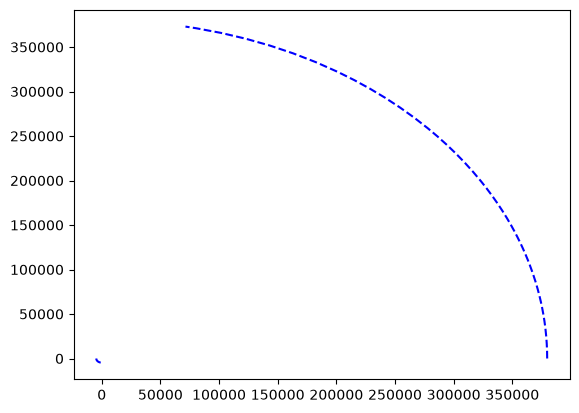

In [53]:
plt.plot(sol_inertial.y[6], sol_inertial.y[7], 'b--', label='Trajectory')
plt.plot(sol_inertial.y[8], sol_inertial.y[9], 'b--', label='Trajectory')